In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import re

In [44]:
def ene_force_n_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   

    energies=[]
    n_atom_per_structure=[]
    mean_module_square=[]
    atom_count=0
    struct_count=0
    tmp=0
    for i , line in enumerate(lines):
        
        if line.startswith('atom'):
            split_line=line.split()
            #print(split_line)
            tmp=tmp+  float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2
            
            #print(tmp)
            atom_count=atom_count+1
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
            energies.append(float(split_line[1]))
            mean_module_square.append(tmp/atom_count)
            n_atom_per_structure.append(atom_count)
            struct_count=struct_count+1
            
            atom_count=0 
            tmp=0
    print(struct_count)
            
       
            
        
    

In [45]:
def atomic_force_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   
    n_atom=[]
    
    H=re.compile(r"H")
    O=re.compile(r"O")
    Fe=re.compile(r"Fe")
    
    atom_count=0
    struct_count=0
   
    mean_H_forces=[]
    mean_O_forces=[]
    mean_Fe_forces=[]
    
    
    H_forces=[]
    O_forces=[]
    Fe_forces=[]
    
    H_tmp=[]
    O_tmp=[]
    Fe_tmp=[]
    
    for i , line in enumerate(lines):
        
        if line.startswith('atom'):
            #print(line)
            split_line=line.split()
    
            atom_count=atom_count+1
            if H.search(line):
                #print(line)
                H_tmp.append( float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2)
            if O.search(line):
                #print(line)
                O_tmp.append( float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2)
            if Fe.search(line):
                #print(line)
                Fe_tmp.append( float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2)
                
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
         
            
            H_forces.append(H_tmp) 
            O_forces.append(O_tmp) 
            Fe_forces.append(Fe_tmp) 
            
            mean_H_forces.append(np.mean(H_tmp))
            mean_O_forces.append(np.mean(O_tmp))
            mean_Fe_forces.append(np.mean(Fe_tmp))
            
            n_atom.append(atom_count)
            struct_count=struct_count+1
            atom_count=0 
            
            H_tmp=[]
            O_tmp=[]
            Fe_tmp=[]
    print("Total number of structures: {}".format(struct_count))
            
       
            
        
    
    return   mean_H_forces ,mean_O_forces, mean_Fe_forces , np.transpose(H_forces), np.transpose(O_forces), np.transpose(Fe_forces),  n_atom

In [47]:
dataset_file='./input.data_MEGA_CLEANED_FOR+ENE_FINAL'




mean_H_forces ,mean_O_forces, mean_Fe_forces, H_forces, O_forces, Fe__forces, n_atom =atomic_force_analysis(dataset_file)



Total number of structures: 21850


In [48]:
#divide by N-atom the dataset

list_atom_number=np.sort(list(set(n_atom)))

print("number of atoms in structures in dataset = {}".format(list_atom_number))

n_ordered_input_index=[]
for i, n in enumerate(list_atom_number):
    n_ordered_input_index.append(np.where(np.array(n_atom) == n)[0])
    print("With {}, {}    structures".format(n,len(n_ordered_input_index[i])))

number of atoms in structures in dataset = [114 126 132 138 144 150 156 162 186 210 234 384]
With 114, 1478    structures
With 126, 1229    structures
With 132, 1897    structures
With 138, 2448    structures
With 144, 3265    structures
With 150, 2516    structures
With 156, 3063    structures
With 162, 687    structures
With 186, 735    structures
With 210, 855    structures
With 234, 2483    structures
With 384, 1194    structures


In [49]:
n_ordered_H_forces=[]
n_ordered_O_forces=[]
n_ordered_Fe_forces=[]

for i, n in enumerate(list_atom_number):
    n_ordered_H_forces.append(np.array(mean_H_forces)[n_ordered_input_index[i]] )
    n_ordered_O_forces.append(np.array(mean_O_forces)[n_ordered_input_index[i]] )
    n_ordered_Fe_forces.append(np.array(mean_Fe_forces)[n_ordered_input_index[i]] )
   

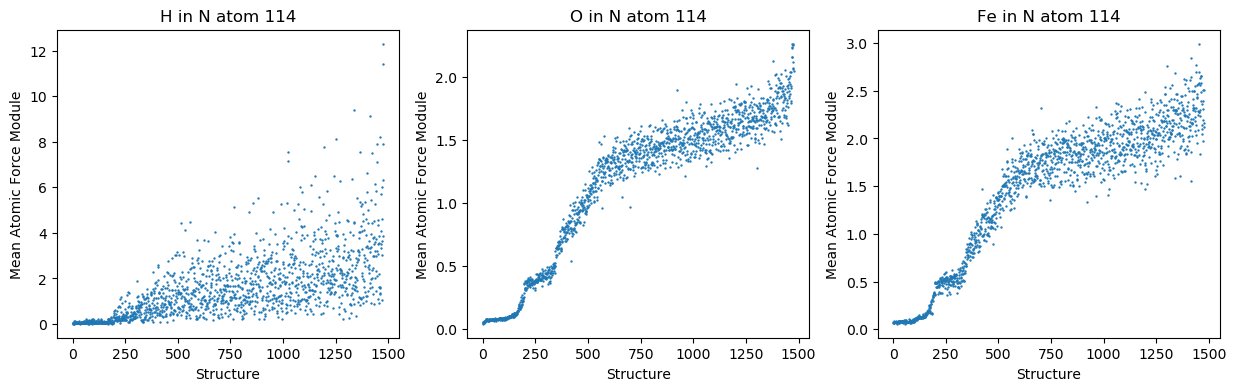

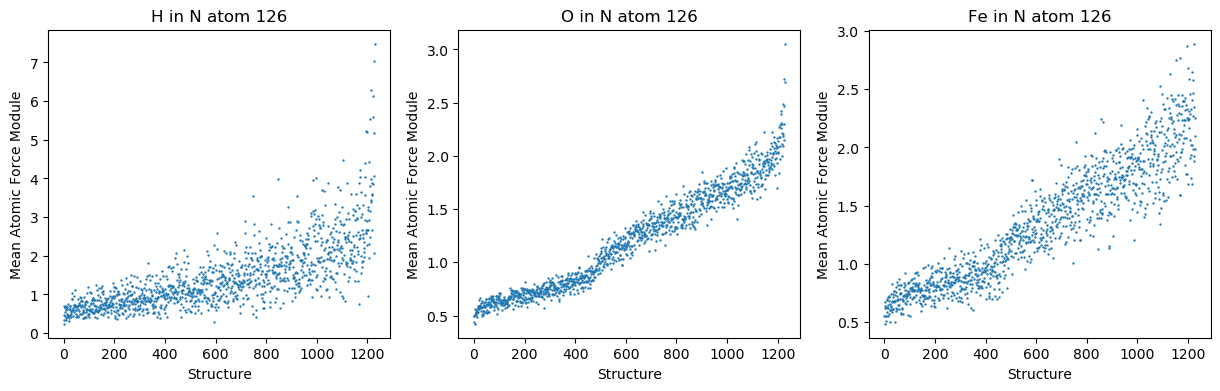

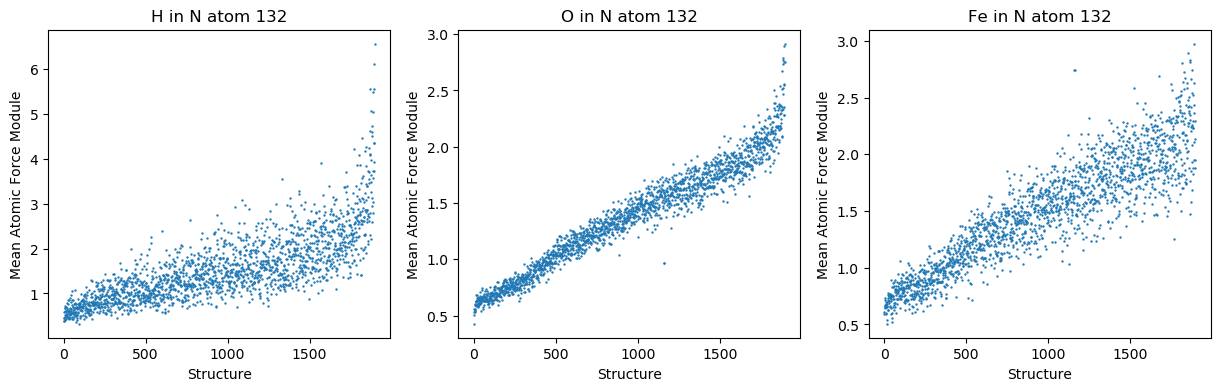

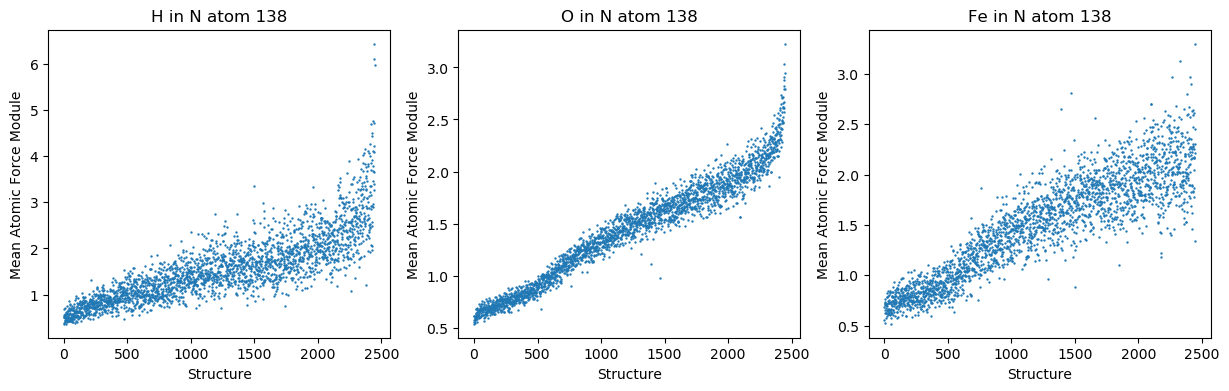

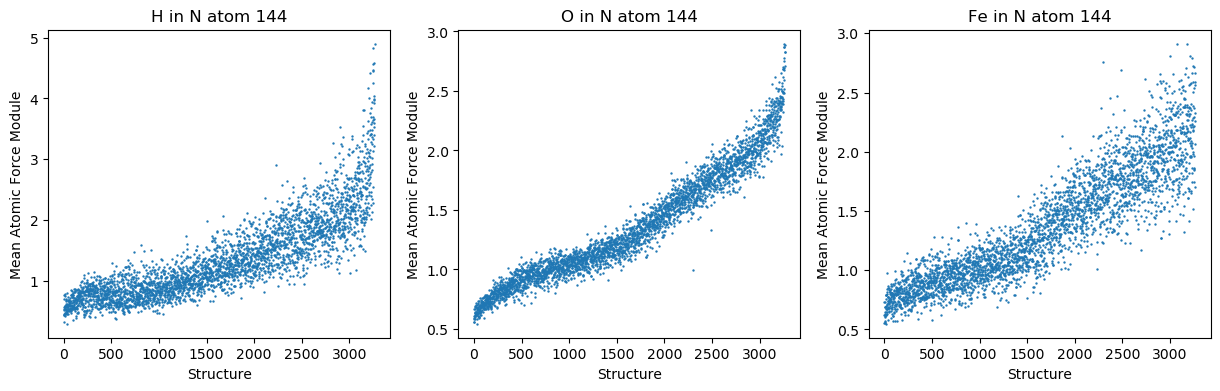

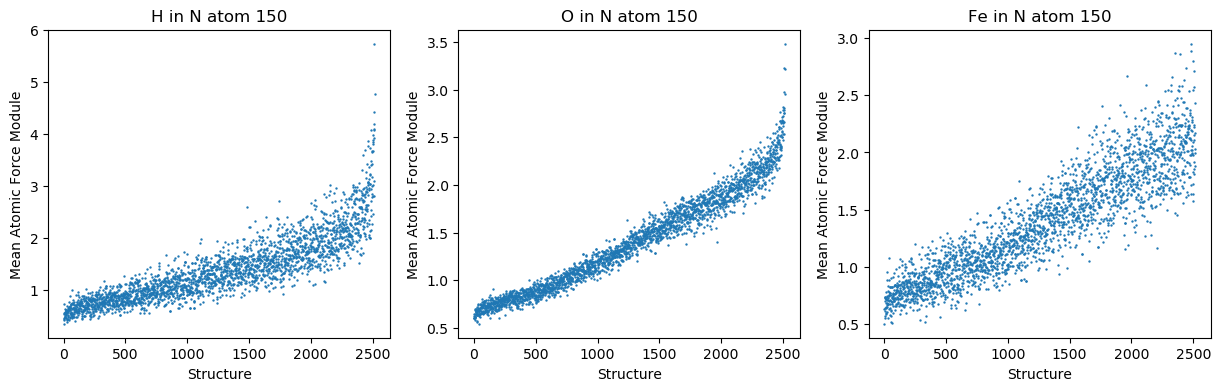

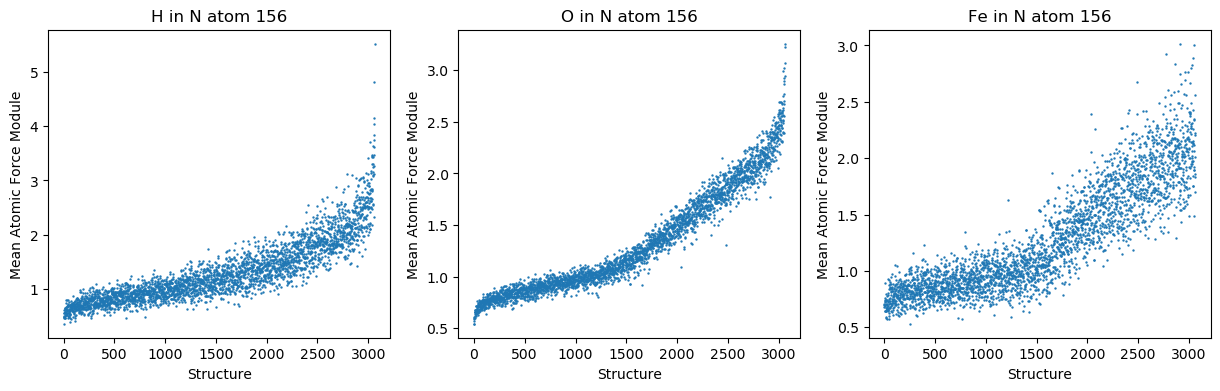

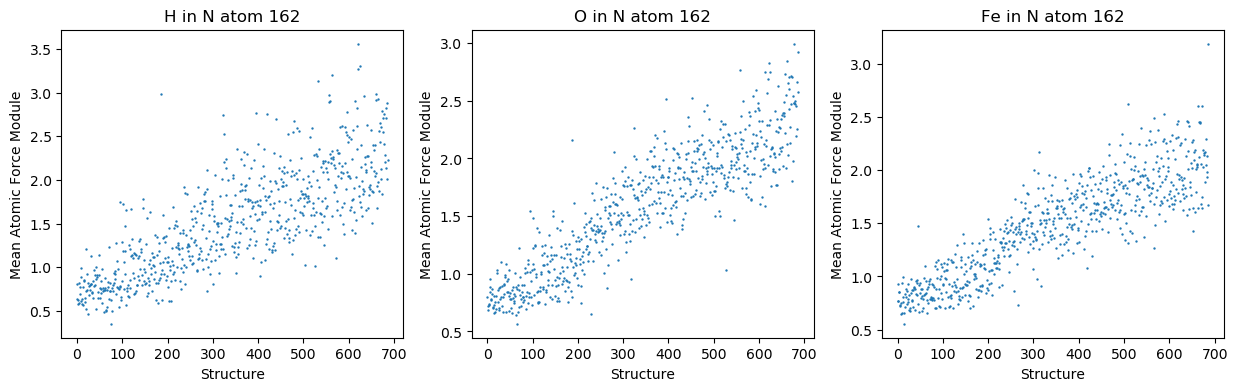

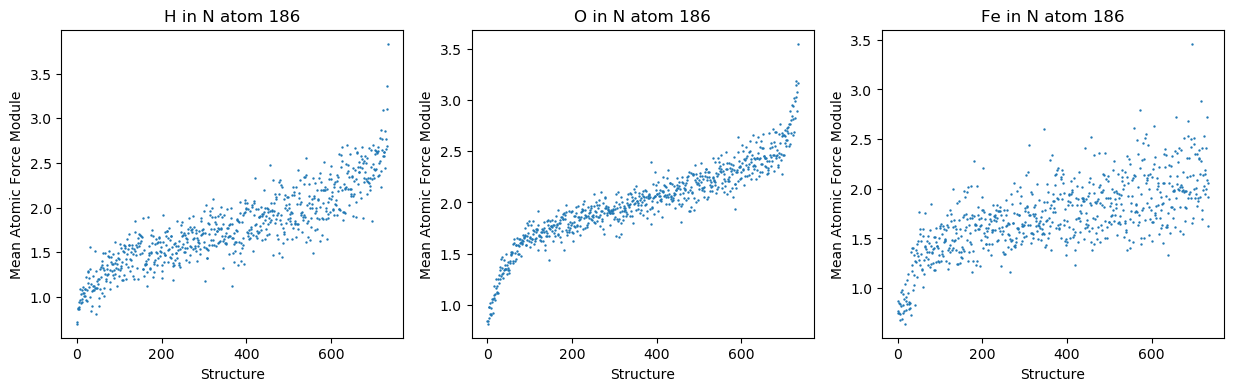

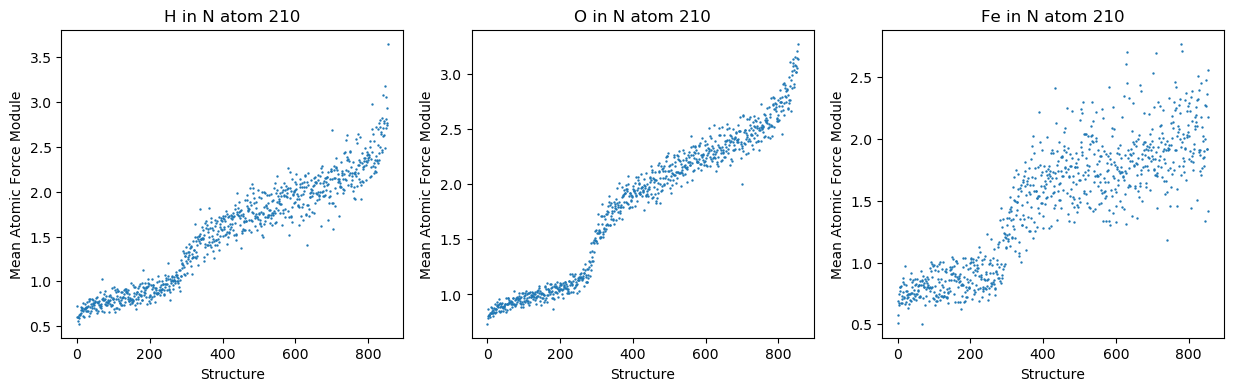

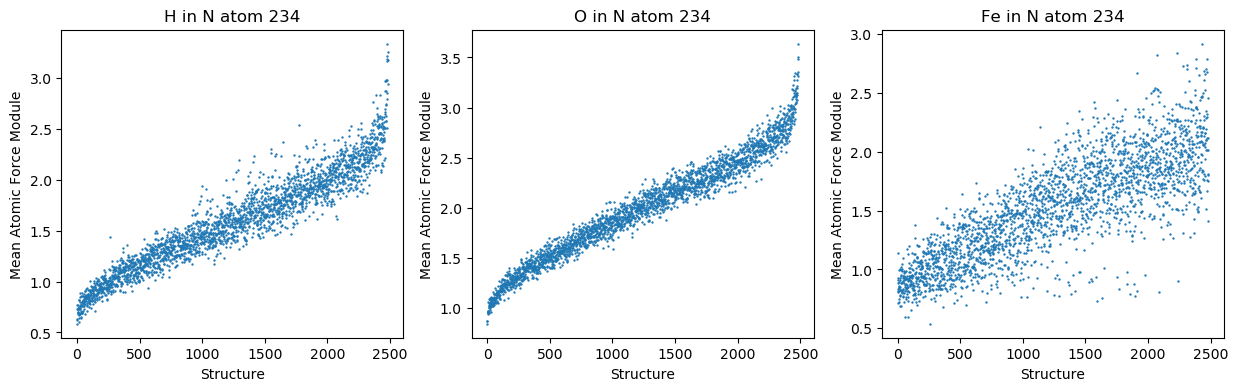

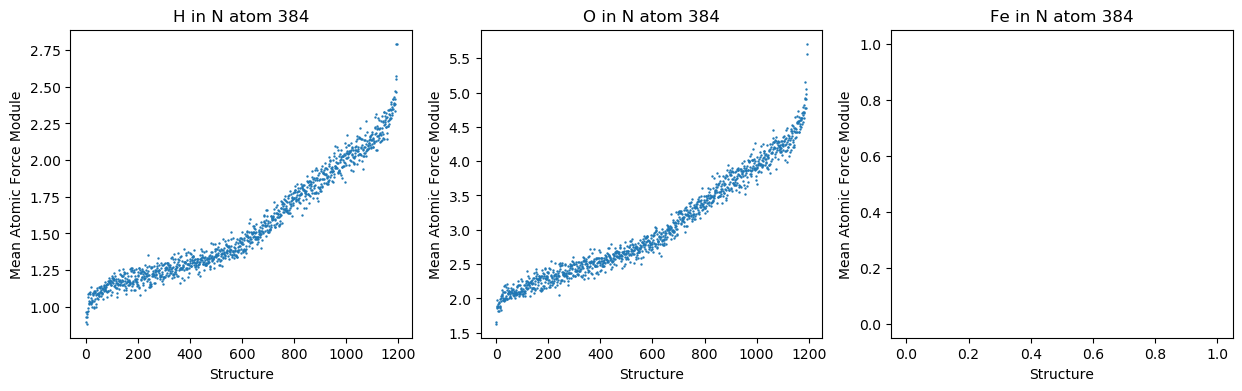

In [50]:
# Number of plots
forces_H_O_Fe=[n_ordered_H_forces, n_ordered_O_forces,   n_ordered_Fe_forces  ]
num_plots = len(forces_H_O_Fe)
name=[ 'H', 'O', 'Fe'  ]

for i, n in enumerate(list_atom_number):
    # Set up subplots
    fig, axes = plt.subplots(1, num_plots, figsize=(15, 4))  
    # Loop through the data and plot on each subplot
    for k, ax in enumerate(axes):
        ax.scatter(np.arange(len(forces_H_O_Fe[k][i])),forces_H_O_Fe[k][i], s = 0.5)
        ax.set_title(f'{name[k]} in N atom {n}')
        ax.set_xlabel('Structure')
        ax.set_ylabel('Mean Atomic Force Module')

# Show the plots
plt.show()

In [ ]:
plt.scatter(np.arange(len(n_ordered_H_forces[i])),n_ordered_H_forces[i], s = 0.5)

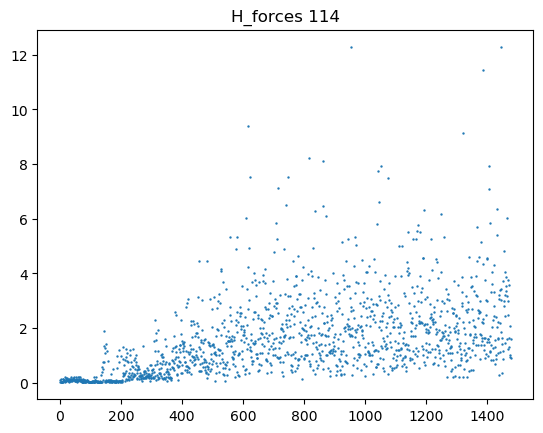

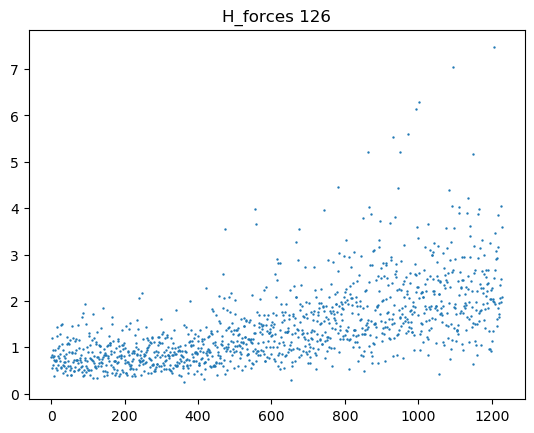

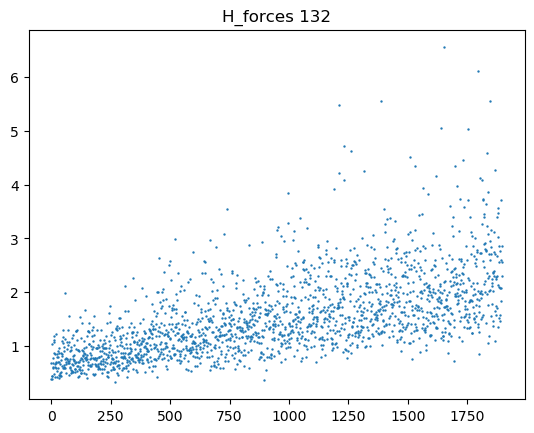

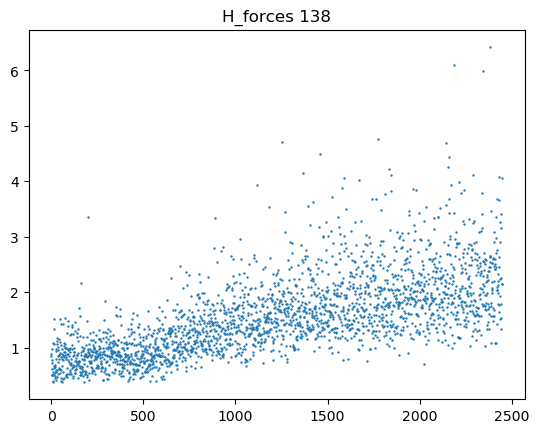

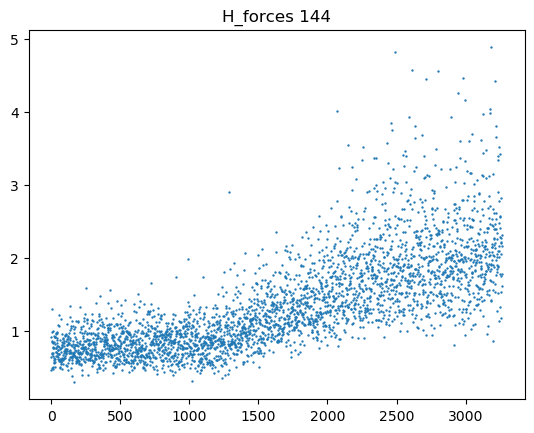

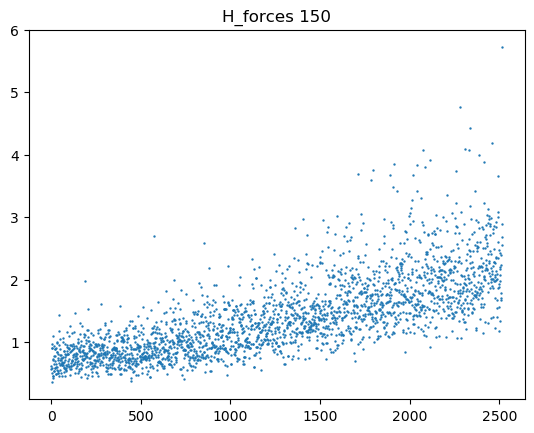

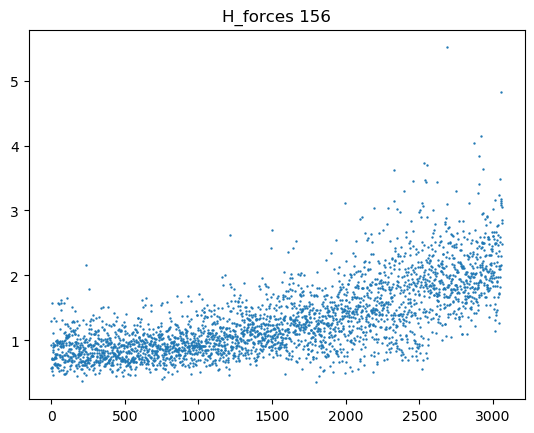

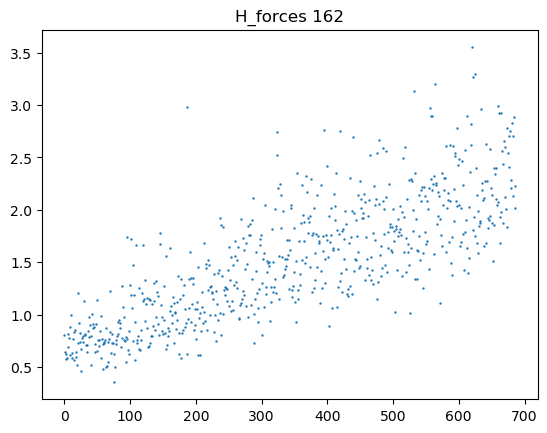

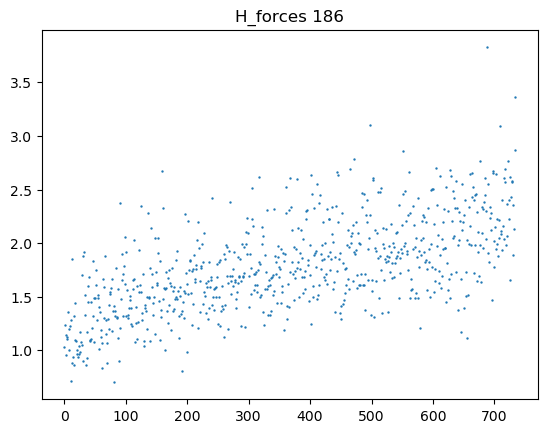

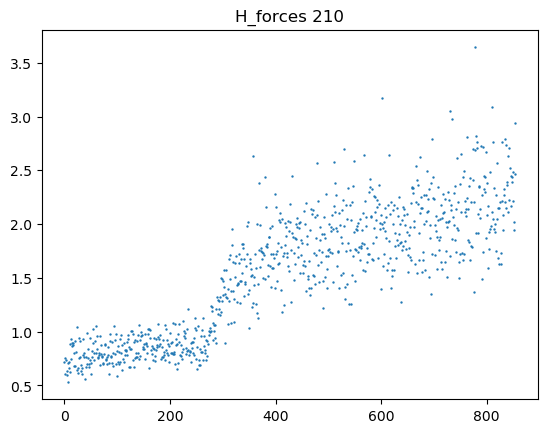

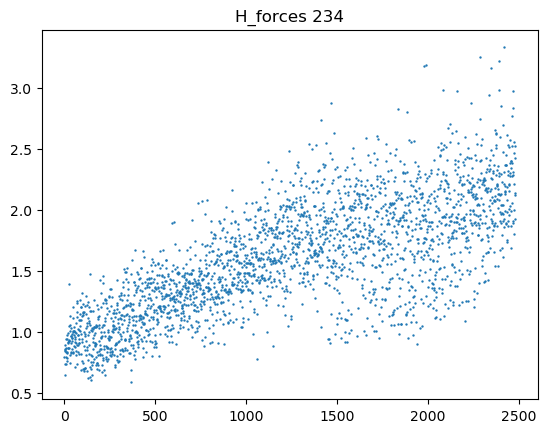

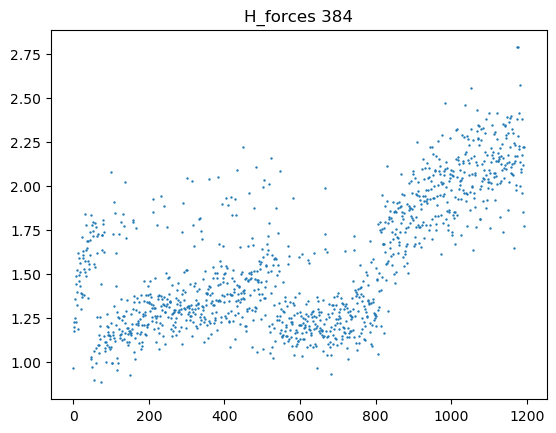

In [20]:
for i, n in enumerate(list_atom_number):
    plt.figure(i+1)
    plt.scatter(np.arange(len(n_ordered_H_forces[i])),n_ordered_H_forces[i], s = 0.5)
    
    plt.title('H_forces {}'.format(n))

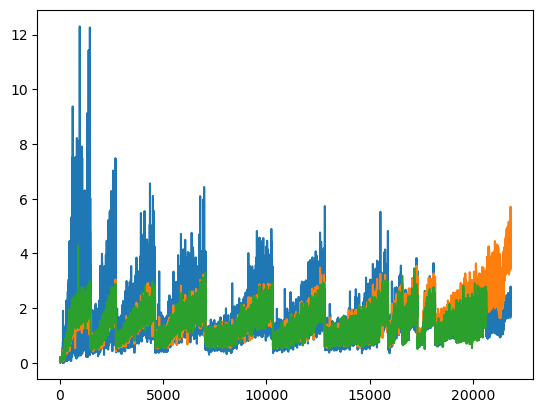

In [9]:
plt.plot(mean_H_forces)
plt.plot(mean_O_forces)
plt.plot(mean_Fe_forces)

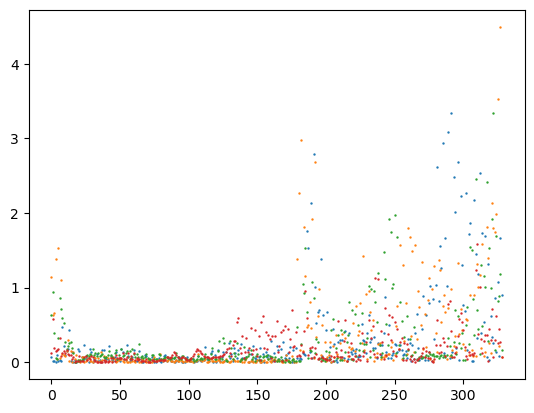

In [179]:
for i in range(len(H_force)):
    plt.scatter(np.arange(len(H_force[i])), H_force[i] , s=0.5)

In [176]:
len(H_force)

4

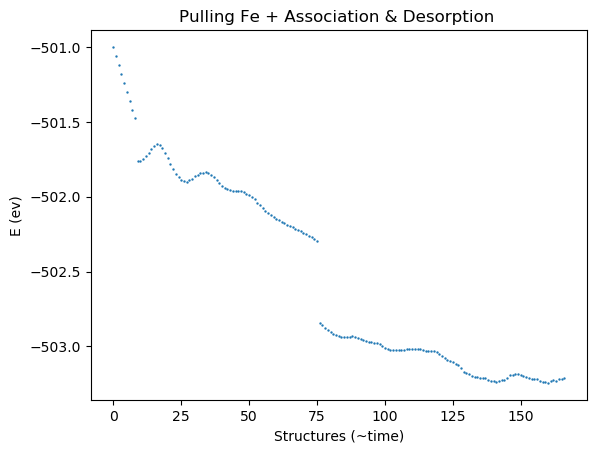

In [128]:
plt.scatter(np.arange(len(energies[8:175])), energies[8:175] , s=0.5)
#plt.ylim(1.3,1.5)
#plt.ylim(0,1.2)
plt.xlabel('Structures (~time)')
plt.ylabel('E (ev)')
plt.title('Pulling Fe + Association & Desorption ')
plt.savefig( 'pull_ass')

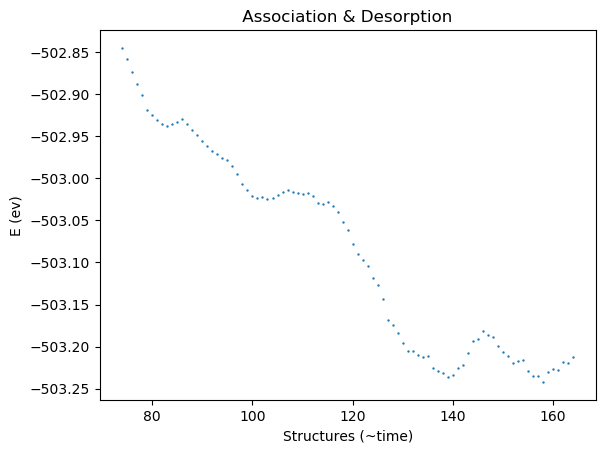

In [126]:
plt.scatter(np.arange(74, 165), energies[84:175] , s=0.5)
#plt.ylim(1.3,1.5)
#plt.ylim(0,1.2)
plt.xlabel('Structures (~time)')
plt.ylabel('E (ev)')
plt.title(' Association & Desorption ')
plt.savefig( 'ass')

In [41]:
good_indices=np.where(np.array(mean_force) < 8)[0]

In [60]:
print(len(good_indices))

329


In [43]:


good_forces=np.array(mean_force)[good_indices]

(299, 310)

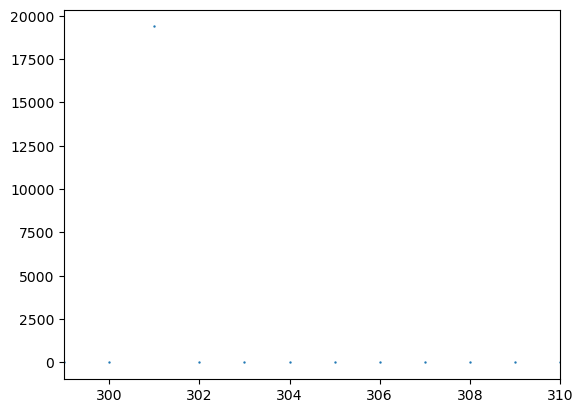

In [51]:
plt.scatter(np.arange(len(mean_force)), mean_force, s=0.5)
#plt.plot(good_forces)
plt.xlim(299,310)

In [52]:
def print_configurations(dataset_file, structures, good_input_data, control):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
    struct_count=0
    not_count=0   
    #print(index)
    with open(good_input_data, 'w') as new_file:
        index=0
        
        for i, line in enumerate(lines):
            if line.startswith('begin'): 
                if index in structures:
                    if control:
                        bool=True
                    else:
                        bool=False
                    struct_count+=1
                else: 
                    if control:
                        bool=False
                    else:
                        bool=True
                    not_count += 1
                index += 1
            if bool:
                new_file.write(line)
    print("old lenght:", index)    
    print(" str lenght:",struct_count )       
    if control:
        print("new lenght:",struct_count) 
    else:
        print("new lenght:",not_count) 
        
    
    return 

In [53]:
#dataset_file="input.data"           #name of the input.data to be cleaned
structure_list=   good_indices      #list of structure indices (containing zero structure) or if file.txt np.loadtxt("name of file txt")
new_input_data="clean.data"                            #name of the output file 
control= True   #set True to print the structures in structure_list, False to print all except from those
print_configurations(dataset_file, structure_list, new_input_data, control)

old lenght: 330
 str lenght: 329
new lenght: 329
